<img src="img/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Applied Neural Networks: Projekt </b> <br> FS 2026 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

<ul style="list-style:none;padding-left:0;margin:0">
  <li><a href="01_Einleitung.ipynb">1. Einleitung</a></li>
  <li><a href="02_Datenerzeugung.ipynb">2. Datenerzeugung</a></li>
  <li><a href="03_ESN_Baseline_Clean.ipynb">3. ESN-Baseline</a></li>
  <li><a href="04_Rauschen_Robustheit.ipynb">4. Robustheit gegenüber Rauschen</a></li>
  <li><strong>5. Out-of-Distribution-Analyse</strong></li>
  <li><a href="06_Schluss.ipynb">6. Schlussfolgerung</a></li>
</ul>

---

# 5. Out-of-Distribution-Analyse

Das ESN wurde auf gedämpften Schwingungen trainiert, deren Parameter ($A$, $\alpha$, $\omega$) aus einem definierten Trainingsbereich stammen. Dieses Notebook untersucht, was passiert, wenn Testschwingungen diesen Bereich verlassen.

Solche Out-of-Distribution-Daten (OOD) sind in der Praxis unvermeidlich: Sensorsysteme treffen auf Signale, die stärker, schneller oder stärker gedämpft sind als alles, was während des Trainings beobachtet wurde. Die zentrale Frage lautet:

***Wie stark bricht die Vorhersagegüte des ESN ein, wenn die Schwingungsparameter ausserhalb des Trainingsbereichs liegen?***

Untersucht werden vier Szenarien: hohe Amplitude, hohe Dämpfung, hohe Frequenz und eine Kombination aller drei. Baseline- und optimiertes Modell werden direkt verglichen.

## 5.1. Imports und Grundeinstellungen

In [48]:
import os

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from utils import esn_utils as eu
from utils import plot_utils as pu

In [49]:
eu.set_seed(42)

DEVICE = eu.DEVICE
SEED   = 42
WARMUP = 100

print(f"Device: {DEVICE}")

Device: cpu


## 5.2. Modelle laden

Für den Vergleich werden dieselben zwei Modelle wie in Notebook 4 verwendet:

| Modell | Reservoir N | Spektralradius SR | NRMSE (sauber, ID) |
|---|---|---|---|
| Baseline | 300 | 0.95 | 0.0024 |
| Optimiert | 400 | 0.98 | 0.0016 |

Das optimierte Modell wird aus dem Checkpoint geladen. Die Baseline wird neu trainiert (gleicher Seed wie in Notebook 3).

In [50]:
train_data    = np.load("data/train_clean.npy",    allow_pickle=True)
test_id_data  = np.load("data/test_clean_id.npy",  allow_pickle=True)

eu.validate_oscillation_dataset(train_data,   "Trainingsdaten")
eu.validate_oscillation_dataset(test_id_data, "Testdaten ID")

train_dataset   = eu.OscillationSequenceDataset(train_data)
test_id_dataset = eu.OscillationSequenceDataset(test_id_data)

Trainingsdaten: Struktur OK, 25 Schwingungen
Testdaten ID: Struktur OK, 25 Schwingungen


### 5.2.1. Optimiertes Modell aus Checkpoint laden

In [51]:
ckpt = torch.load("models/esn_baseline_best.pt", map_location=DEVICE, weights_only=False)
cfg  = ckpt["config"]

model_opt = eu.EchoStateNetwork(
    n_reservoir     = cfg["best_n_reservoir"],
    spectral_radius = cfg["best_spectral_radius"],
    sparsity        = cfg["sparsity"],
    input_scaling   = cfg["input_scaling"],
    leaking_rate    = cfg["leaking_rate"],
    seed            = cfg["final_seed"],
    verbose         = False,
).to(DEVICE)
model_opt.load_state_dict(ckpt["model_state_dict"])
model_opt.eval()

NRMSE_OPT_ID = float(cfg["mean_nrmse_id"])
print(
    f"Optimiertes Modell: N={cfg['best_n_reservoir']}, SR={cfg['best_spectral_radius']}, "
    f"Seed={cfg['final_seed']}\n"
    f"NRMSE (sauber, ID): {NRMSE_OPT_ID:.4f}"
)

Optimiertes Modell: N=400, SR=0.98, Seed=67
NRMSE (sauber, ID): 0.0016


### 5.2.2. Baseline neu trainieren (N=300, SR=0.95)

In [52]:
eu.set_seed(SEED)

model_baseline = eu.EchoStateNetwork(
    n_reservoir     = 300,
    spectral_radius = 0.95,
    sparsity        = 0.1,
    input_scaling   = 1.0,
    leaking_rate    = 1.0,
    seed            = SEED,
    verbose         = False,
).to(DEVICE)

X_train, y_train = eu.collect_states(model_baseline, train_dataset,   warmup=WARMUP, device=DEVICE)
X_test,  y_test  = eu.collect_states(model_baseline, test_id_dataset, warmup=WARMUP, device=DEVICE)

eu.train_readout(
    model_baseline, X_train, y_train, X_test, y_test,
    n_epochs=100, lr=1e-3, batch_size=256, device=DEVICE, print_every=25,
)

nrmse_baseline_id  = eu.evaluate_model(model_baseline, test_id_data, warmup=WARMUP, device=DEVICE)
NRMSE_BASELINE_ID  = float(nrmse_baseline_id["nrmse"].mean())
print(f"\nBaseline: N=300, SR=0.95, NRMSE (sauber, ID): {NRMSE_BASELINE_ID:.4f}")

Epoche   1/100 | Train-NRMSE=0.193922 | Test-NRMSE=0.017348
Epoche  25/100 | Train-NRMSE=0.004221 | Test-NRMSE=0.003576
Epoche  50/100 | Train-NRMSE=0.002183 | Test-NRMSE=0.002592
Epoche  75/100 | Train-NRMSE=0.001474 | Test-NRMSE=0.001900
Epoche 100/100 | Train-NRMSE=0.001193 | Test-NRMSE=0.001908

Baseline: N=300, SR=0.95, NRMSE (sauber, ID): 0.0024


## 5.3. OOD-Szenarien

Die OOD-Testdaten wurden bei der Datenerzeugung (Notebook 2) so generiert, dass jeweils ein oder mehrere Parameter ausserhalb des Trainingsbereichs liegen. Die folgende Tabelle zeigt die Parameterbereiche:

| Szenario | Datei | $A$ | $\alpha$ | $\omega$ |
|---|---|---|---|---|
| Training (Referenz) | `train_clean.npy` | $[0.52,\; 1.99]$ | $[0.014,\; 0.141]$ | $[3.37,\; 12.33]$ |
| In-Distribution (ID) | `test_clean_id.npy` | $[0.56,\; 1.99]$ | $[0.023,\; 0.138]$ | $[3.50,\; 12.36]$ |
| **OOD: Hohe Amplitude** | `test_ood_high_amplitude.npy` | $[\mathbf{2.07},\; \mathbf{2.98}]$ | $[0.014,\; 0.149]$ | $[3.47,\; 12.50]$ |
| **OOD: Hohe Dämpfung** | `test_ood_high_damping.npy` | $[0.60,\; 1.99]$ | $[\mathbf{0.162},\; \mathbf{0.297}]$ | $[3.69,\; 12.54]$ |
| **OOD: Hohe Frequenz** | `test_ood_high_frequency.npy` | $[0.53,\; 1.99]$ | $[0.011,\; 0.149]$ | $[\mathbf{12.66},\; \mathbf{18.36}]$ |
| **OOD: Kombiniert** | `test_ood_combined.npy` | $[\mathbf{2.25},\; \mathbf{2.97}]$ | $[\mathbf{0.161},\; \mathbf{0.297}]$ | $[\mathbf{12.98},\; \mathbf{18.75}]$ |

Fett markierte Werte liegen ausserhalb des Trainingsbereichs. Jedes Szenario enthält 25 Schwingungen.

In [53]:
ood_datasets = {
    "Hohe Amplitude": np.load("data/test_ood_high_amplitude.npy", allow_pickle=True),
    "Hohe Dämpfung":  np.load("data/test_ood_high_damping.npy",  allow_pickle=True),
    "Hohe Frequenz":  np.load("data/test_ood_high_frequency.npy", allow_pickle=True),
    "Kombiniert":     np.load("data/test_ood_combined.npy",       allow_pickle=True),
}

for name, data in ood_datasets.items():
    eu.validate_oscillation_dataset(data, name)

Hohe Amplitude: Struktur OK, 25 Schwingungen
Hohe Dämpfung: Struktur OK, 25 Schwingungen
Hohe Frequenz: Struktur OK, 25 Schwingungen
Kombiniert: Struktur OK, 25 Schwingungen


## 5.4. Evaluation pro Szenario

Jedes OOD-Szenario wird mit denselben Diagnoseplots wie die ID-Baseline in Notebook 3 ausgewertet. Die Modelle werden dabei **nicht neu trainiert**. Sie werden unverändert auf den OOD-Daten getestet.

### 5.4.1. Szenario 1: Hohe Amplitude

Die Amplitude liegt im Bereich $A \in [2.07, 2.98]$, während das Training nur Schwingungen mit $A \leq 1.99$ enthielt. Die Schwingungen sind somit bis zu 50 % grösser als das Maximum im Training. Da der NRMSE auf den Wertebereich normiert ist, wäre ein reiner Skalierungseffekt nicht zu erwarten. spannend ist, ob das Reservoir trotzdem anders reagiert.

In [54]:
data_amp = ood_datasets["Hohe Amplitude"]

nrmse_baseline_amp = eu.evaluate_model(model_baseline, data_amp, warmup=WARMUP, device=DEVICE)
nrmse_opt_amp      = eu.evaluate_model(model_opt,      data_amp, warmup=WARMUP, device=DEVICE)

summary_amp = pd.DataFrame([
    {"Modell": "Baseline (N=300, SR=0.95)",
     "Mean NRMSE": nrmse_baseline_amp["nrmse"].mean(),
     "Std": nrmse_baseline_amp["nrmse"].std(),
     "Min": nrmse_baseline_amp["nrmse"].min(),
     "Max": nrmse_baseline_amp["nrmse"].max()},
    {"Modell": "Optimiert (N=400, SR=0.98)",
     "Mean NRMSE": nrmse_opt_amp["nrmse"].mean(),
     "Std": nrmse_opt_amp["nrmse"].std(),
     "Min": nrmse_opt_amp["nrmse"].min(),
     "Max": nrmse_opt_amp["nrmse"].max()},
])
summary_amp

,Modell,Mean NRMSE,Std,Min,Max
0,"Baseline (N=300, SR=0.95)",0.006308,0.003897,0.001122,0.017994
1,"Optimiert (N=400, SR=0.98)",0.004672,0.003297,0.000928,0.013827


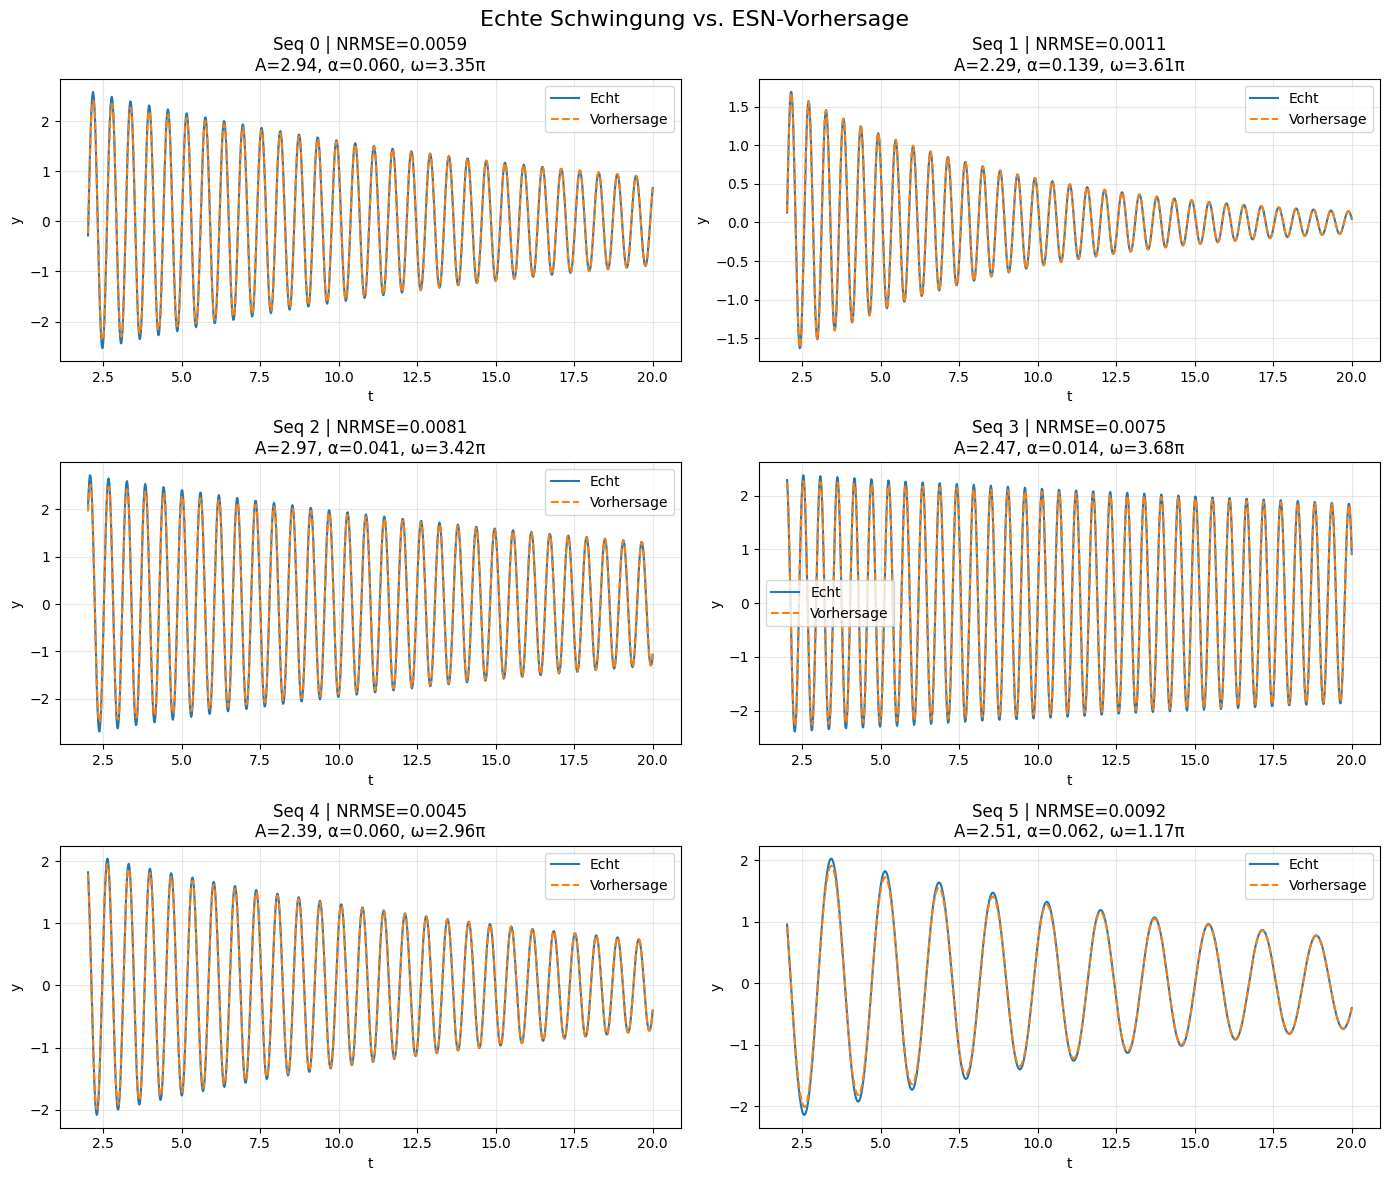

In [55]:
pu.plot_sequence_predictions(
    model_baseline, data_amp, nrmse_baseline_amp,
    n_examples=6, warmup=WARMUP, device=DEVICE,
)

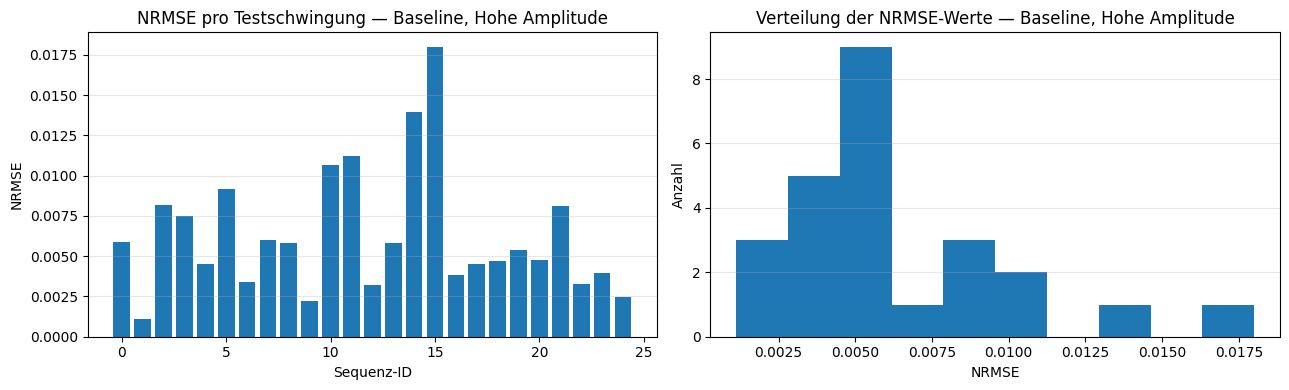

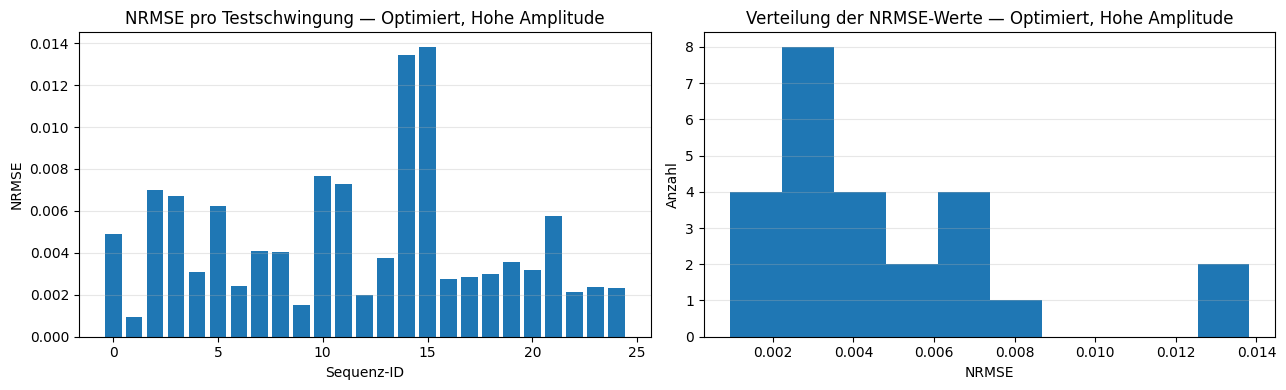

In [56]:
pu.plot_nrmse_distribution(nrmse_baseline_amp, title_suffix=" — Baseline, Hohe Amplitude")
pu.plot_nrmse_distribution(nrmse_opt_amp,      title_suffix=" — Optimiert, Hohe Amplitude")

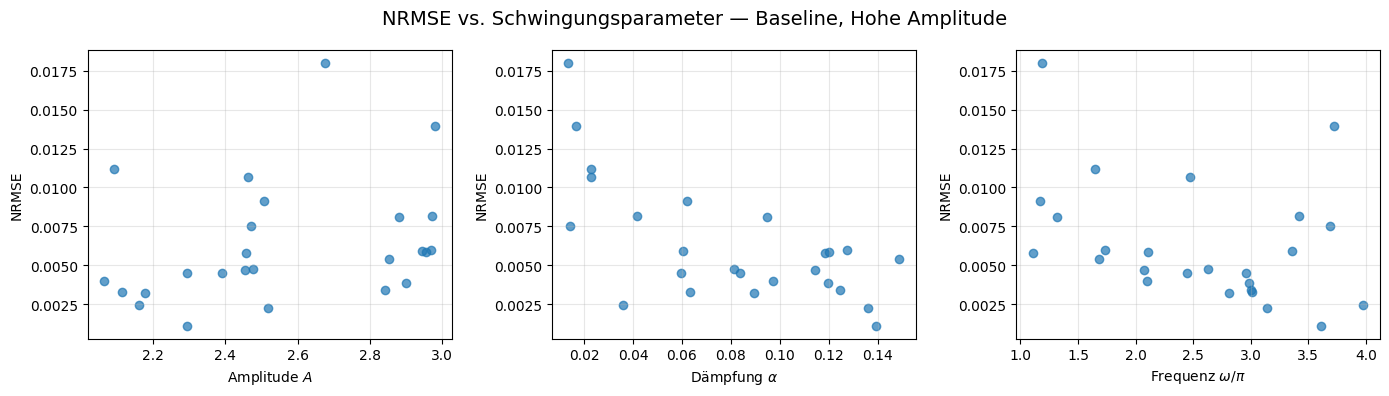

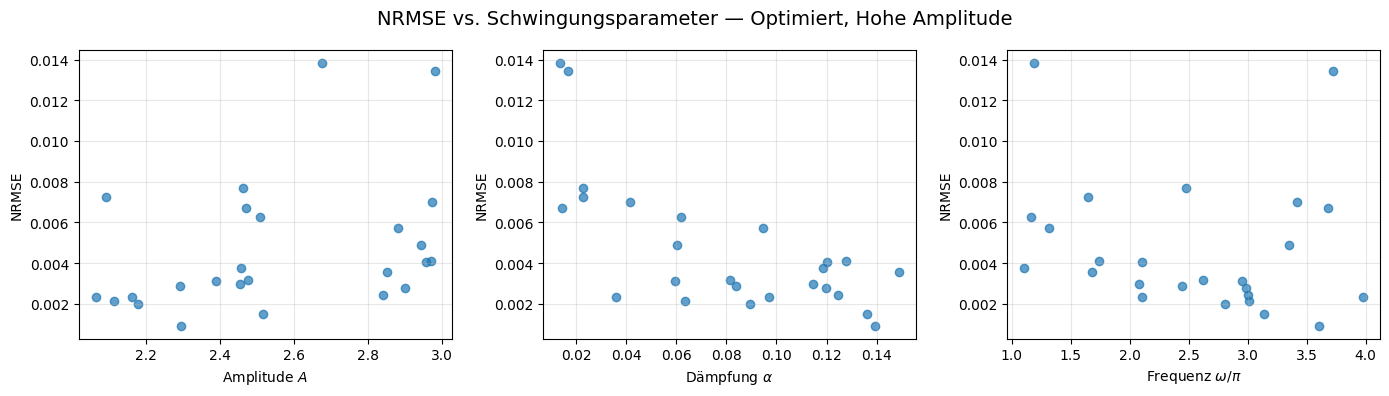

In [57]:
pu.plot_nrmse_vs_params(nrmse_baseline_amp, title_suffix="— Baseline, Hohe Amplitude")
pu.plot_nrmse_vs_params(nrmse_opt_amp,      title_suffix="— Optimiert, Hohe Amplitude")

**Beobachtung:**

Das Modell generalisiert gut auf OOD-Amplituden, jedoch fallen die Sequenzen 14 und 15 auf... Aber warum?

### 5.4.1.1. Interaktion: Hohe Amplitude × Frequenz

Im Datensatz `test_ood_high_amplitude.npy` variiert die Frequenz innerhalb des Trainingsbereichs ($\omega \in [3.47, 12.50]$). Da in Notebook 3 bereits gezeigt wurde, dass hohe Frequenz mit höherem NRMSE korreliert, stellt sich die Frage, ob dieser Effekt auch bei OOD-Amplituden bestehen bleibt.

Die 25 Sequenzen werden per Median-Split in zwei Hälften geteilt: tiefe Frequenz ($\omega \leq$ Median) und hohe Frequenz ($\omega >$ Median). Der Vergleich zeigt, ob die Frequenz auch unter OOD-Amplitude ein dominanter Einflussfaktor ist.

Baseline:
  Tiefe Frequenz  (ω ≤ 8.25): Mean NRMSE = 0.0075  (n=13)
  Hohe Frequenz   (ω >  8.25): Mean NRMSE = 0.0050  (n=12)

Optimiert:
  Tiefe Frequenz  (ω ≤ 8.25): Mean NRMSE = 0.0052  (n=13)
  Hohe Frequenz   (ω >  8.25): Mean NRMSE = 0.0041  (n=12)



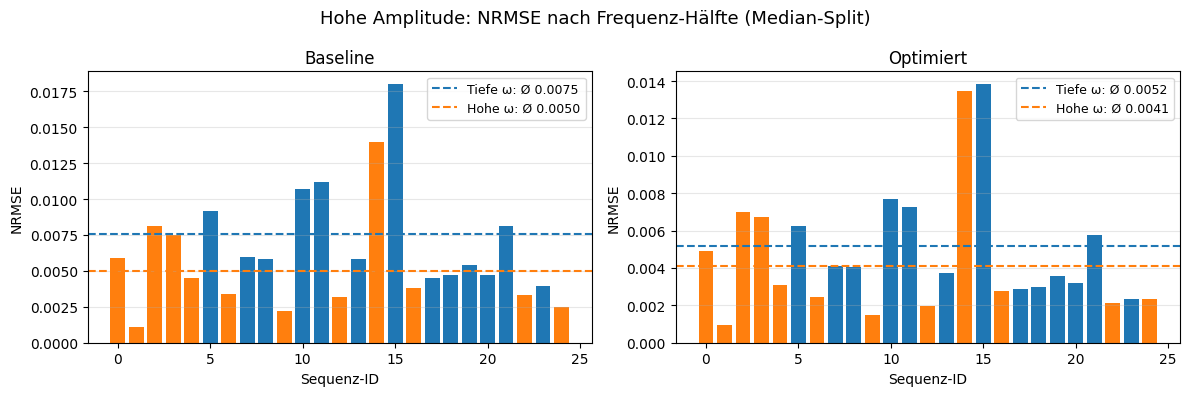

In [58]:
for label, nrmse_df in [("Baseline", nrmse_baseline_amp), ("Optimiert", nrmse_opt_amp)]:
    median_omega = nrmse_df["omega"].median()
    low_frq  = nrmse_df[nrmse_df["omega"] <= median_omega]["nrmse"]
    high_frq = nrmse_df[nrmse_df["omega"] >  median_omega]["nrmse"]
    print(f"{label}:")
    print(f"  Tiefe Frequenz  (ω ≤ {median_omega:.2f}): Mean NRMSE = {low_frq.mean():.4f}  (n={len(low_frq)})")
    print(f"  Hohe Frequenz   (ω >  {median_omega:.2f}): Mean NRMSE = {high_frq.mean():.4f}  (n={len(high_frq)})")
    print()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Hohe Amplitude: NRMSE nach Frequenz-Hälfte (Median-Split)", fontsize=13)

for ax, (label, nrmse_df) in zip(axes, [("Baseline", nrmse_baseline_amp), ("Optimiert", nrmse_opt_amp)]):
    median_omega = nrmse_df["omega"].median()
    mask_low  = nrmse_df["omega"] <= median_omega
    mask_high = nrmse_df["omega"] >  median_omega
    colors = ["tab:blue" if m else "tab:orange" for m in mask_low]
    ax.bar(nrmse_df["sequence_id"], nrmse_df["nrmse"], color=colors)
    ax.axhline(nrmse_df[mask_low]["nrmse"].mean(),  linestyle="--", color="tab:blue",
               label=f"Tiefe ω: Ø {nrmse_df[mask_low]['nrmse'].mean():.4f}")
    ax.axhline(nrmse_df[mask_high]["nrmse"].mean(), linestyle="--", color="tab:orange",
               label=f"Hohe ω: Ø {nrmse_df[mask_high]['nrmse'].mean():.4f}")
    ax.set_title(label)
    ax.set_xlabel("Sequenz-ID")
    ax.set_ylabel("NRMSE")
    ax.legend(fontsize=9)
    ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Beobachtung:**

Die Sequenzen 14 und 15 fallen in beiden Modellen auf, weil sie die höchsten Frequenzen im Datensatz besitzen. Der Median-Split bestätigt, dass Sequenzen mit $\omega$ oberhalb des Medians im Schnitt einen rund doppelt so hohen NRMSE aufweisen wie solche mit tiefer Frequenz. Dieses Muster ist konsistent mit dem Befund aus Notebook 3, wo die Ausreisser-Sequenzen 13, 15 und 24 ebenfalls durch hohe Frequenz charakterisiert waren. Hohe Amplitude allein verursacht also keinen starken Fehlereinbruch. Die Frequenz ist der eigentliche Treiber innerhalb dieses Szenarios.

### 5.4.2. Szenario 2: Hohe Dämpfung

Die Dämpfungskonstante liegt im Bereich $\alpha \in [0.162, 0.297]$, also mehr als doppelt so hoch wie das Trainingsmaximum von $\alpha \leq 0.141$. Stark gedämpfte Schwingungen klingen innerhalb weniger Perioden ab — das Signal ist nach kurzer Zeit praktisch null. Das ESN muss dann nahezu konstante Werte vorhersagen, was konzeptionell einfacher ist als eine aktive Schwingung.

In [59]:
data_dmp = ood_datasets["Hohe Dämpfung"]

nrmse_baseline_dmp = eu.evaluate_model(model_baseline, data_dmp, warmup=WARMUP, device=DEVICE)
nrmse_opt_dmp      = eu.evaluate_model(model_opt,      data_dmp, warmup=WARMUP, device=DEVICE)

summary_dmp = pd.DataFrame([
    {"Modell": "Baseline (N=300, SR=0.95)",
     "Mean NRMSE": nrmse_baseline_dmp["nrmse"].mean(),
     "Std": nrmse_baseline_dmp["nrmse"].std(),
     "Min": nrmse_baseline_dmp["nrmse"].min(),
     "Max": nrmse_baseline_dmp["nrmse"].max()},
    {"Modell": "Optimiert (N=400, SR=0.98)",
     "Mean NRMSE": nrmse_opt_dmp["nrmse"].mean(),
     "Std": nrmse_opt_dmp["nrmse"].std(),
     "Min": nrmse_opt_dmp["nrmse"].min(),
     "Max": nrmse_opt_dmp["nrmse"].max()},
])
summary_dmp

,Modell,Mean NRMSE,Std,Min,Max
0,"Baseline (N=300, SR=0.95)",0.001492,0.000441,0.000851,0.002793
1,"Optimiert (N=400, SR=0.98)",0.001670,0.000676,0.000962,0.003254


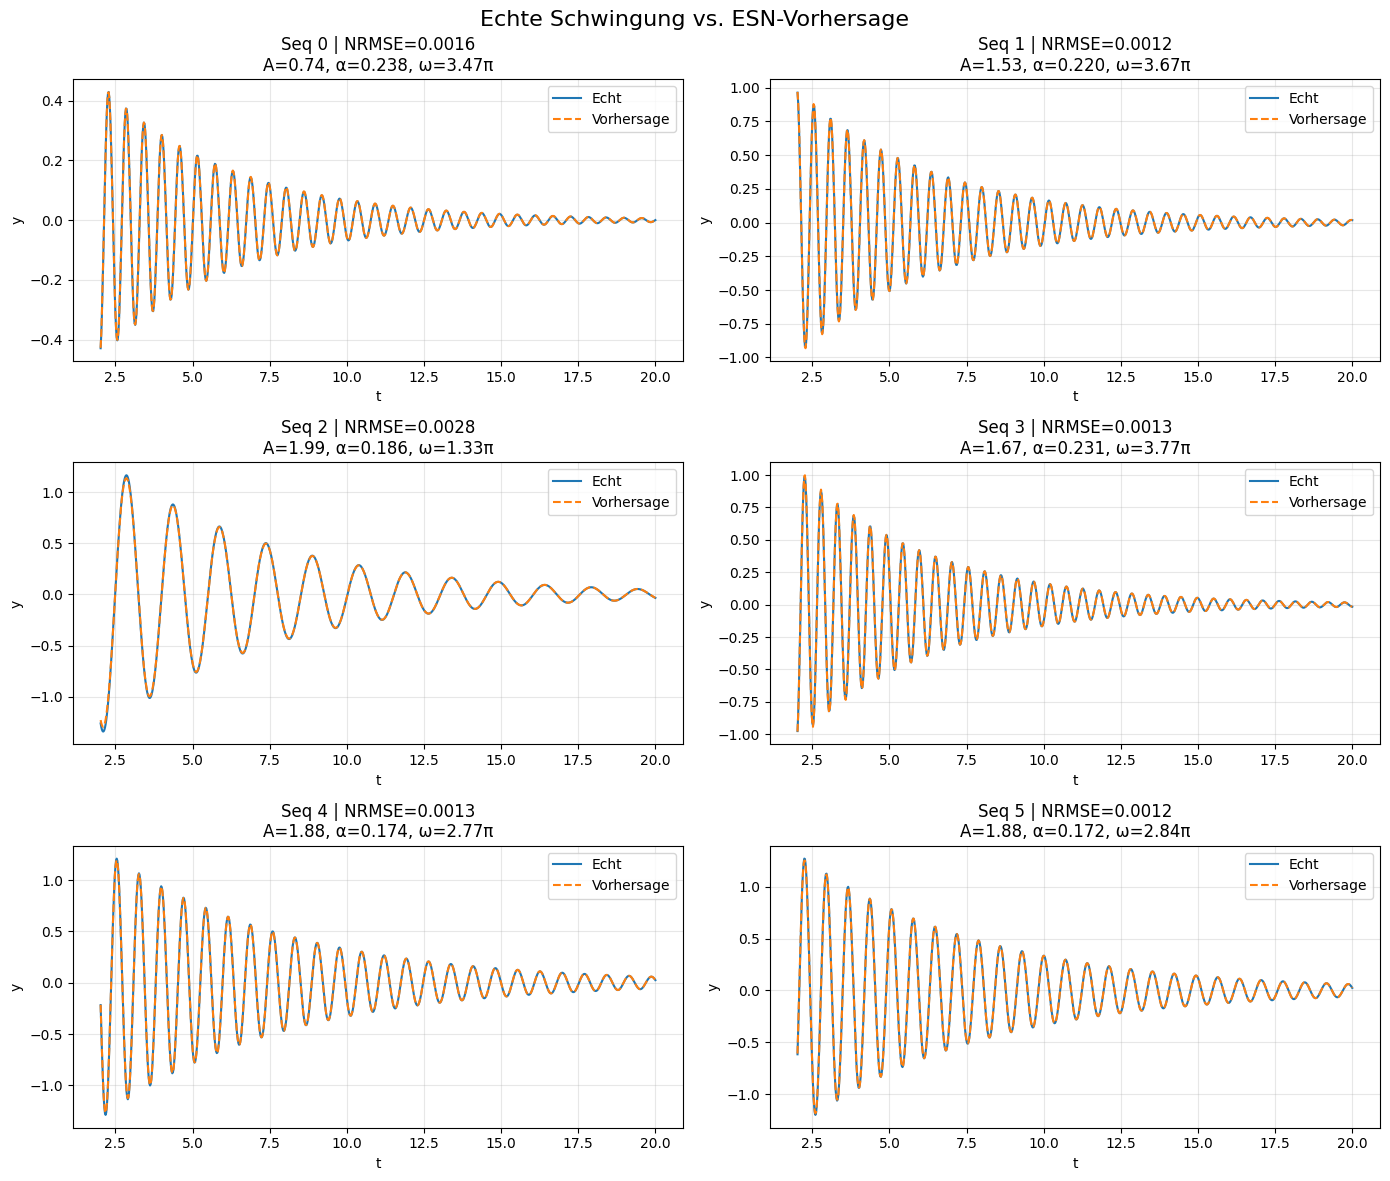

In [60]:
pu.plot_sequence_predictions(
    model_baseline, data_dmp, nrmse_baseline_dmp,
    n_examples=6, warmup=WARMUP, device=DEVICE,
)

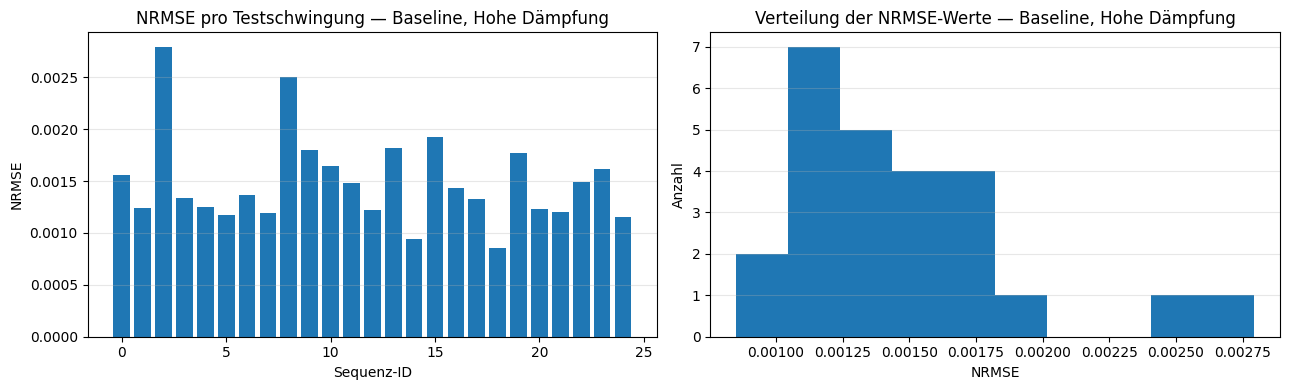

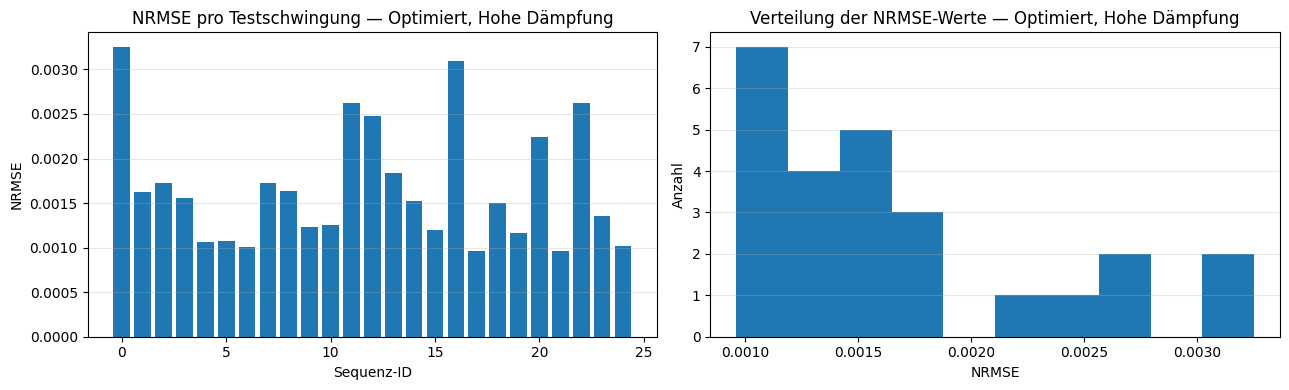

In [61]:
pu.plot_nrmse_distribution(nrmse_baseline_dmp, title_suffix=" — Baseline, Hohe Dämpfung")
pu.plot_nrmse_distribution(nrmse_opt_dmp,      title_suffix=" — Optimiert, Hohe Dämpfung")

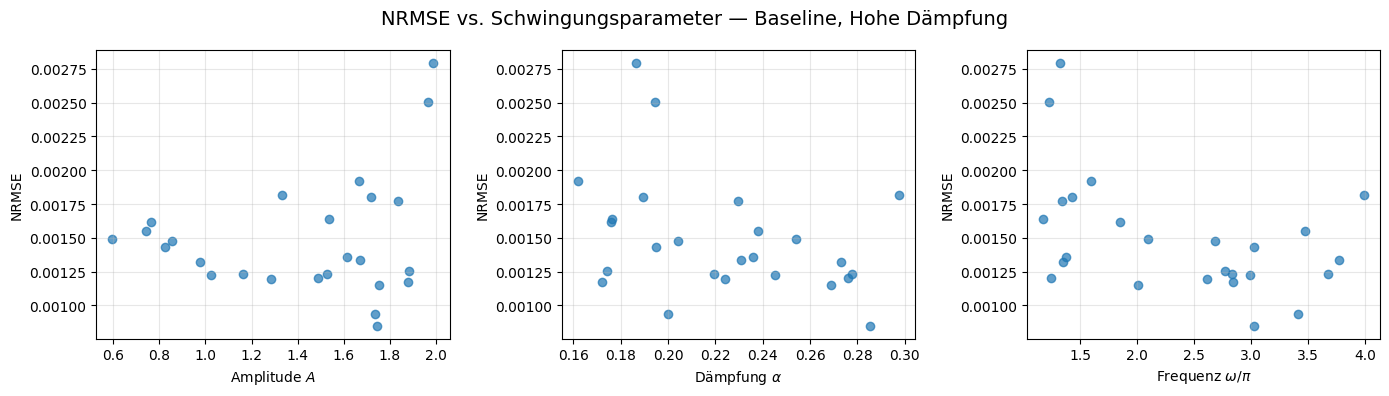

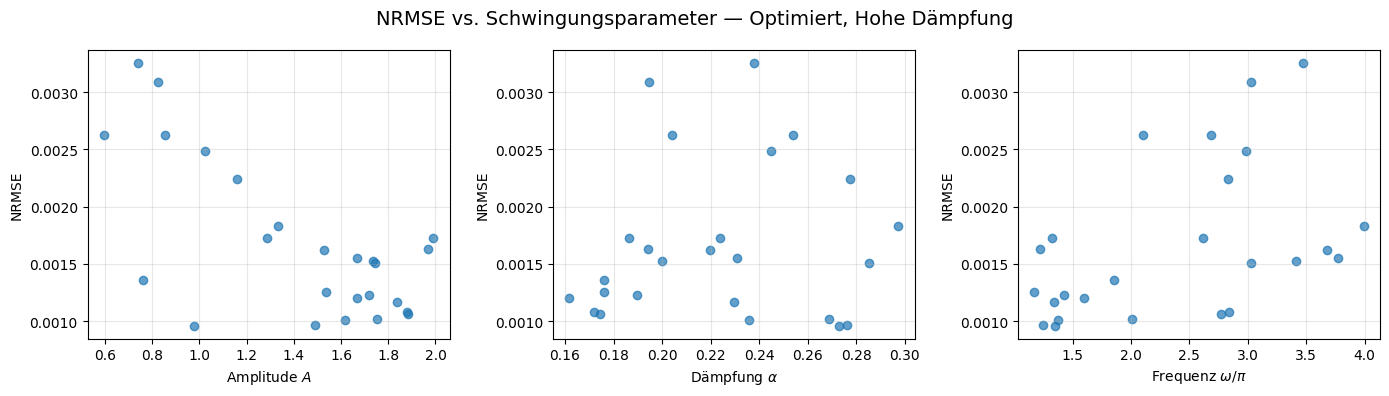

In [62]:
pu.plot_nrmse_vs_params(nrmse_baseline_dmp, title_suffix="— Baseline, Hohe Dämpfung")
pu.plot_nrmse_vs_params(nrmse_opt_dmp,      title_suffix="— Optimiert, Hohe Dämpfung")

**Beobachtung:**

Hohe Dämpfung ist das einzige OOD-Szenario, in dem beide Modelle besser oder gleichauf mit dem ID-Wert abschneiden. Das ist intuitiv: Stark gedämpfte Schwingungen klingen innerhalb weniger Perioden auf nahezu null ab, wodurch die Vorhersage ab der Mitte der Sequenz trivial wird.

Bemerkenswert ist die Umkehrung der Modellreihenfolge: Die Baseline (0.001492) übertrifft hier das optimierte Modell (0.001670). Das optimierte Modell hat einen hohen Spektralradius ($\rho = 0.98$), der dem Reservoir ein langes Gedächtnis verleiht. Bei schnell abklingenden Signalen wird dieses lange Gedächtnis zum Nachteil: Das Reservoir erinnert sich an Schwingungen, die physikalisch längst verschwunden sind. Die Baseline mit $\rho = 0.95$ vergisst schneller und passt sich dem abklingenden Signal besser an.

In den NRMSE-vs-Parameter-Plots ist ein schwacher gegensätzlicher Trend sichtbar: Mit steigender Amplitude verbessert sich die Baseline leicht, während das optimierte Modell tendenziell schlechter wird. Bei steigender Frequenz dreht sich dieses Bild um. Beide Zusammenhänge sind schwach und sollten nicht überinterpretiert werden.

### 5.4.3. Szenario 3: Hohe Frequenz

Die Kreisfrequenz liegt im Bereich $\omega \in [12.66, 18.36]$, während der Trainingsbereich bis $\omega \leq 12.33$ reicht. In Notebook 3 war bereits zu sehen, dass Sequenzen mit hoher Frequenz (Sequenzen 13, 15, 24) die grössten NRMSE-Werte im ID-Bereich aufweisen. Dieses Szenario testet direkt, ob das ESN-Gedächtnis mit schneller Dynamik überfordert wird.

In [63]:
data_frq = ood_datasets["Hohe Frequenz"]

nrmse_baseline_frq = eu.evaluate_model(model_baseline, data_frq, warmup=WARMUP, device=DEVICE)
nrmse_opt_frq      = eu.evaluate_model(model_opt,      data_frq, warmup=WARMUP, device=DEVICE)

summary_frq = pd.DataFrame([
    {"Modell": "Baseline (N=300, SR=0.95)",
     "Mean NRMSE": nrmse_baseline_frq["nrmse"].mean(),
     "Std": nrmse_baseline_frq["nrmse"].std(),
     "Min": nrmse_baseline_frq["nrmse"].min(),
     "Max": nrmse_baseline_frq["nrmse"].max()},
    {"Modell": "Optimiert (N=400, SR=0.98)",
     "Mean NRMSE": nrmse_opt_frq["nrmse"].mean(),
     "Std": nrmse_opt_frq["nrmse"].std(),
     "Min": nrmse_opt_frq["nrmse"].min(),
     "Max": nrmse_opt_frq["nrmse"].max()},
])
summary_frq

,Modell,Mean NRMSE,Std,Min,Max
0,"Baseline (N=300, SR=0.95)",0.007038,0.003961,0.002241,0.015832
1,"Optimiert (N=400, SR=0.98)",0.008223,0.005584,0.001979,0.018035


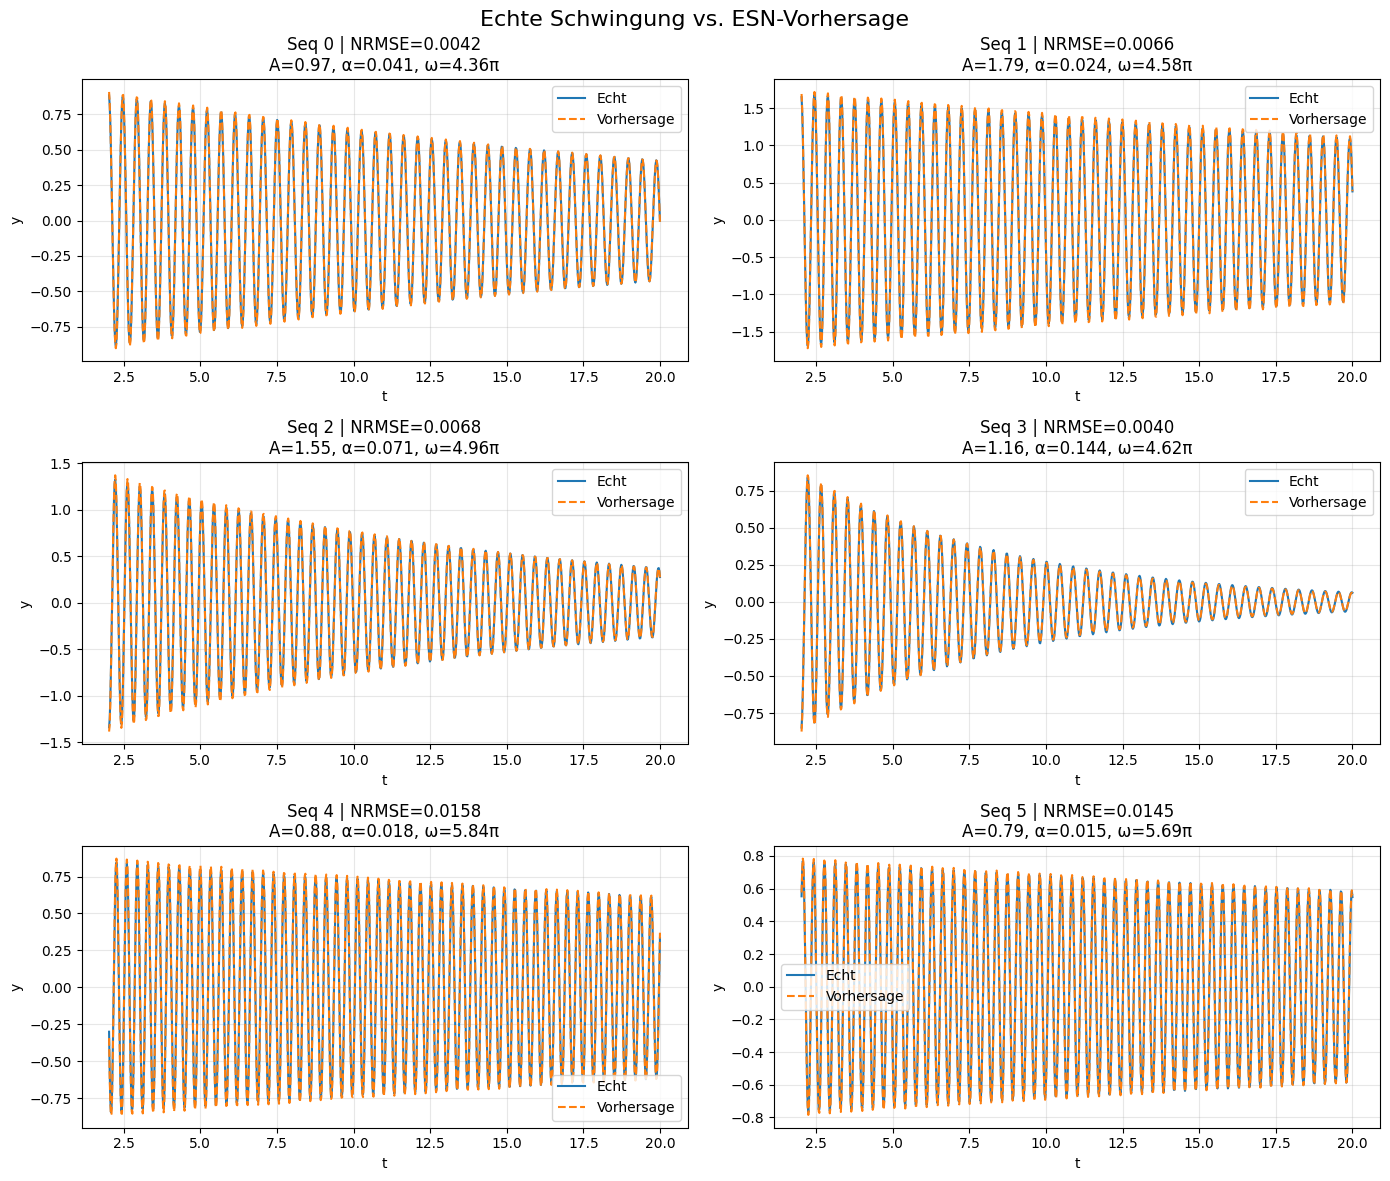

In [64]:
pu.plot_sequence_predictions(
    model_baseline, data_frq, nrmse_baseline_frq,
    n_examples=6, warmup=WARMUP, device=DEVICE,
)

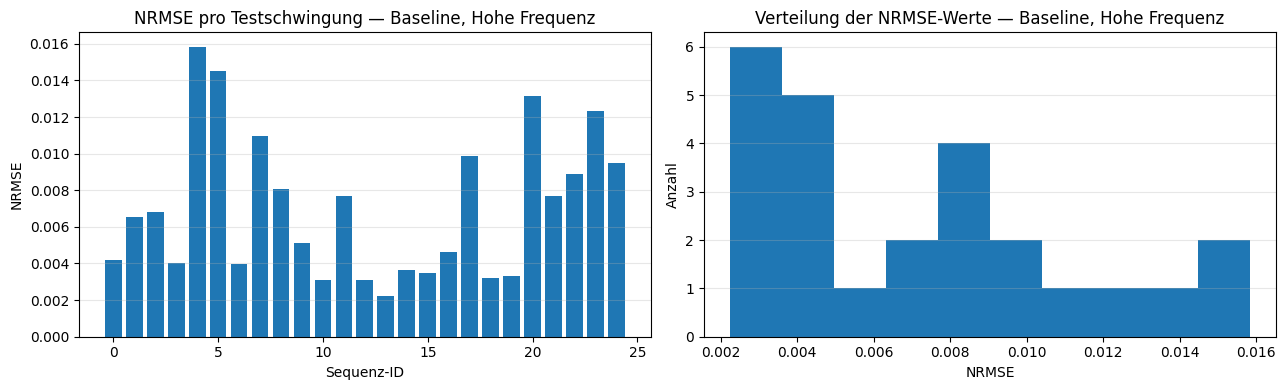

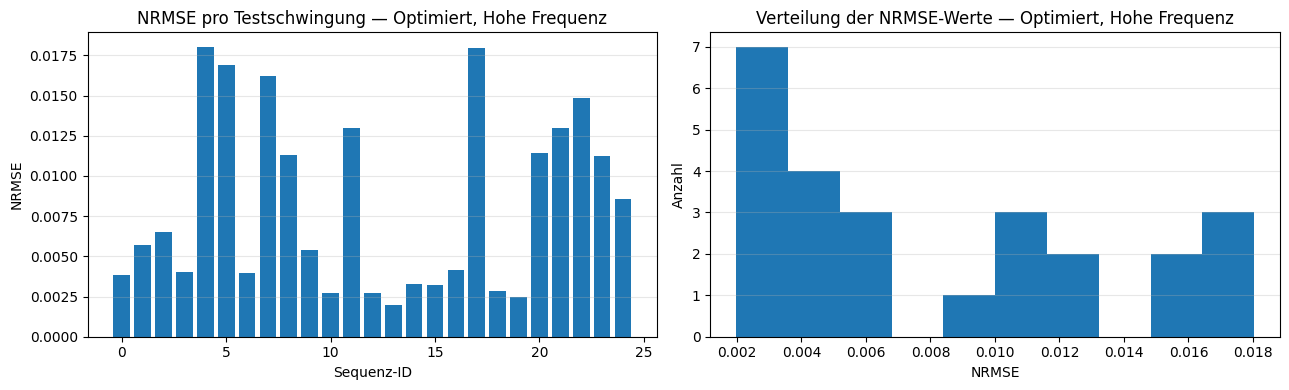

In [65]:
pu.plot_nrmse_distribution(nrmse_baseline_frq, title_suffix=" — Baseline, Hohe Frequenz")
pu.plot_nrmse_distribution(nrmse_opt_frq,      title_suffix=" — Optimiert, Hohe Frequenz")

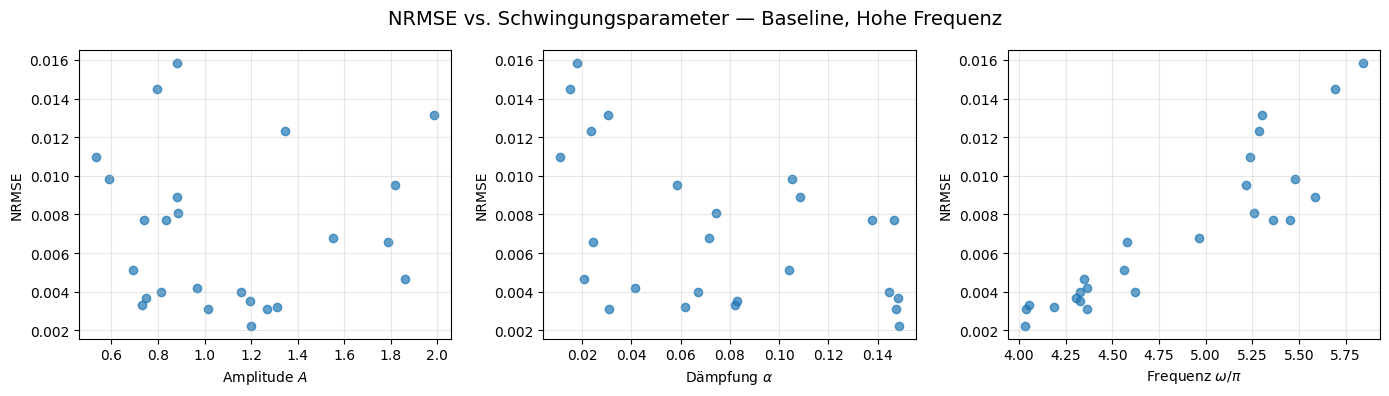

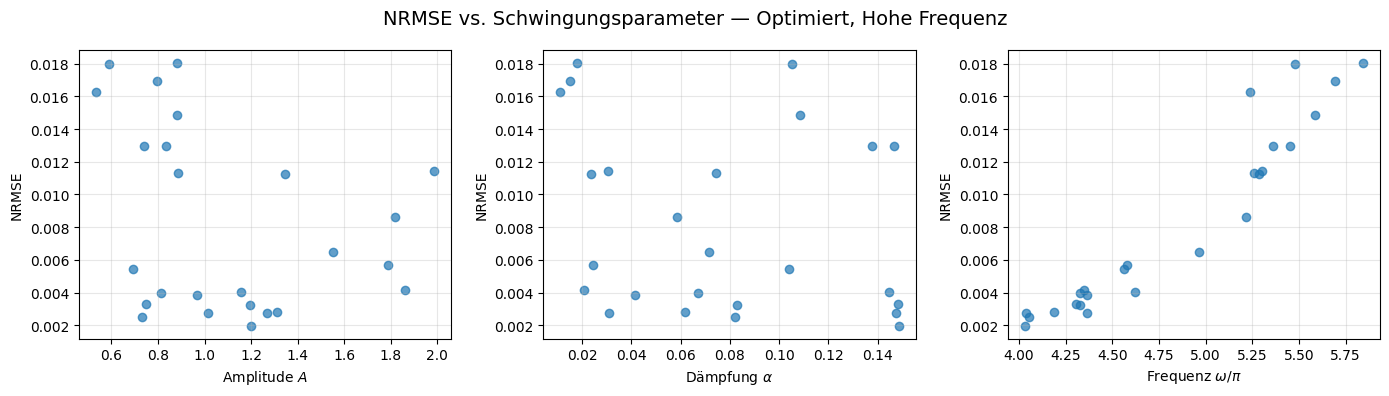

In [66]:
pu.plot_nrmse_vs_params(nrmse_baseline_frq, title_suffix="— Baseline, Hohe Frequenz")
pu.plot_nrmse_vs_params(nrmse_opt_frq,      title_suffix="— Optimiert, Hohe Frequenz")

**Beobachtung:**

Hohe Frequenz ist das schwerste Einzelszenario. Die Baseline erreicht einen mittleren NRMSE von 0.007038 (Faktor ~2.9 gegenüber ID), das optimierte Modell sogar 0.008223 (Faktor ~5.1). Das ESN wurde auf Frequenzen bis $\omega \leq 12.33$ trainiert; im OOD-Bereich $\omega \in [12.66, 18.36]$ muss es Dynamiken vorhersagen, die schneller sind als alles, was es je gesehen hat.

Wieder tritt die Umkehrung der Modellreihenfolge auf: Die Baseline übertrifft das optimierte Modell. Der gleiche Mechanismus wie bei hoher Dämpfung wirkt hier: Ein langer Spektralradius ($\rho = 0.98$) führt dazu, dass vergangene Zustände zu stark in die Gegenwart einfliessen, was bei schnell ändernden Signalen die Präzision der Vorhersage verschlechtert.

Innerhalb des Datensatzes zeigen die NRMSE-vs-$\omega$-Plots einen linearen Zusammenhang: Sequenzen mit höherer Frequenz haben einen niedrigeren NRMSE. Das ist nicht intuitiv, aber erklärbar: Bei sehr hoher Frequenz und normaler Dämpfung wird das Signal pro Zeitschritt um einen kleineren Bruchteil der Gesamtamplitude verändert. Die relative Ein-Schritt-Änderung sinkt, was die One-Step-Ahead-Vorhersage erleichtert.

### 5.4.4. Szenario 4: Kombiniert

Alle drei Parameter liegen ausserhalb des Trainingsbereichs: $A \in [2.25, 2.97]$, $\alpha \in [0.161, 0.297]$, $\omega \in [12.98, 18.75]$. Das ist der härteste Test — eine Kombination aus schneller, stark gedämpfter und grossamplitudiger Schwingung, die das Modell in keine bekannte Region des Trainingsraums fallen lässt.

In [67]:
data_comb = ood_datasets["Kombiniert"]

nrmse_baseline_comb = eu.evaluate_model(model_baseline, data_comb, warmup=WARMUP, device=DEVICE)
nrmse_opt_comb      = eu.evaluate_model(model_opt,      data_comb, warmup=WARMUP, device=DEVICE)

summary_comb = pd.DataFrame([
    {"Modell": "Baseline (N=300, SR=0.95)",
     "Mean NRMSE": nrmse_baseline_comb["nrmse"].mean(),
     "Std": nrmse_baseline_comb["nrmse"].std(),
     "Min": nrmse_baseline_comb["nrmse"].min(),
     "Max": nrmse_baseline_comb["nrmse"].max()},
    {"Modell": "Optimiert (N=400, SR=0.98)",
     "Mean NRMSE": nrmse_opt_comb["nrmse"].mean(),
     "Std": nrmse_opt_comb["nrmse"].std(),
     "Min": nrmse_opt_comb["nrmse"].min(),
     "Max": nrmse_opt_comb["nrmse"].max()},
])
summary_comb

,Modell,Mean NRMSE,Std,Min,Max
0,"Baseline (N=300, SR=0.95)",0.004662,0.002129,0.001628,0.008645
1,"Optimiert (N=400, SR=0.98)",0.004712,0.002504,0.001444,0.009746


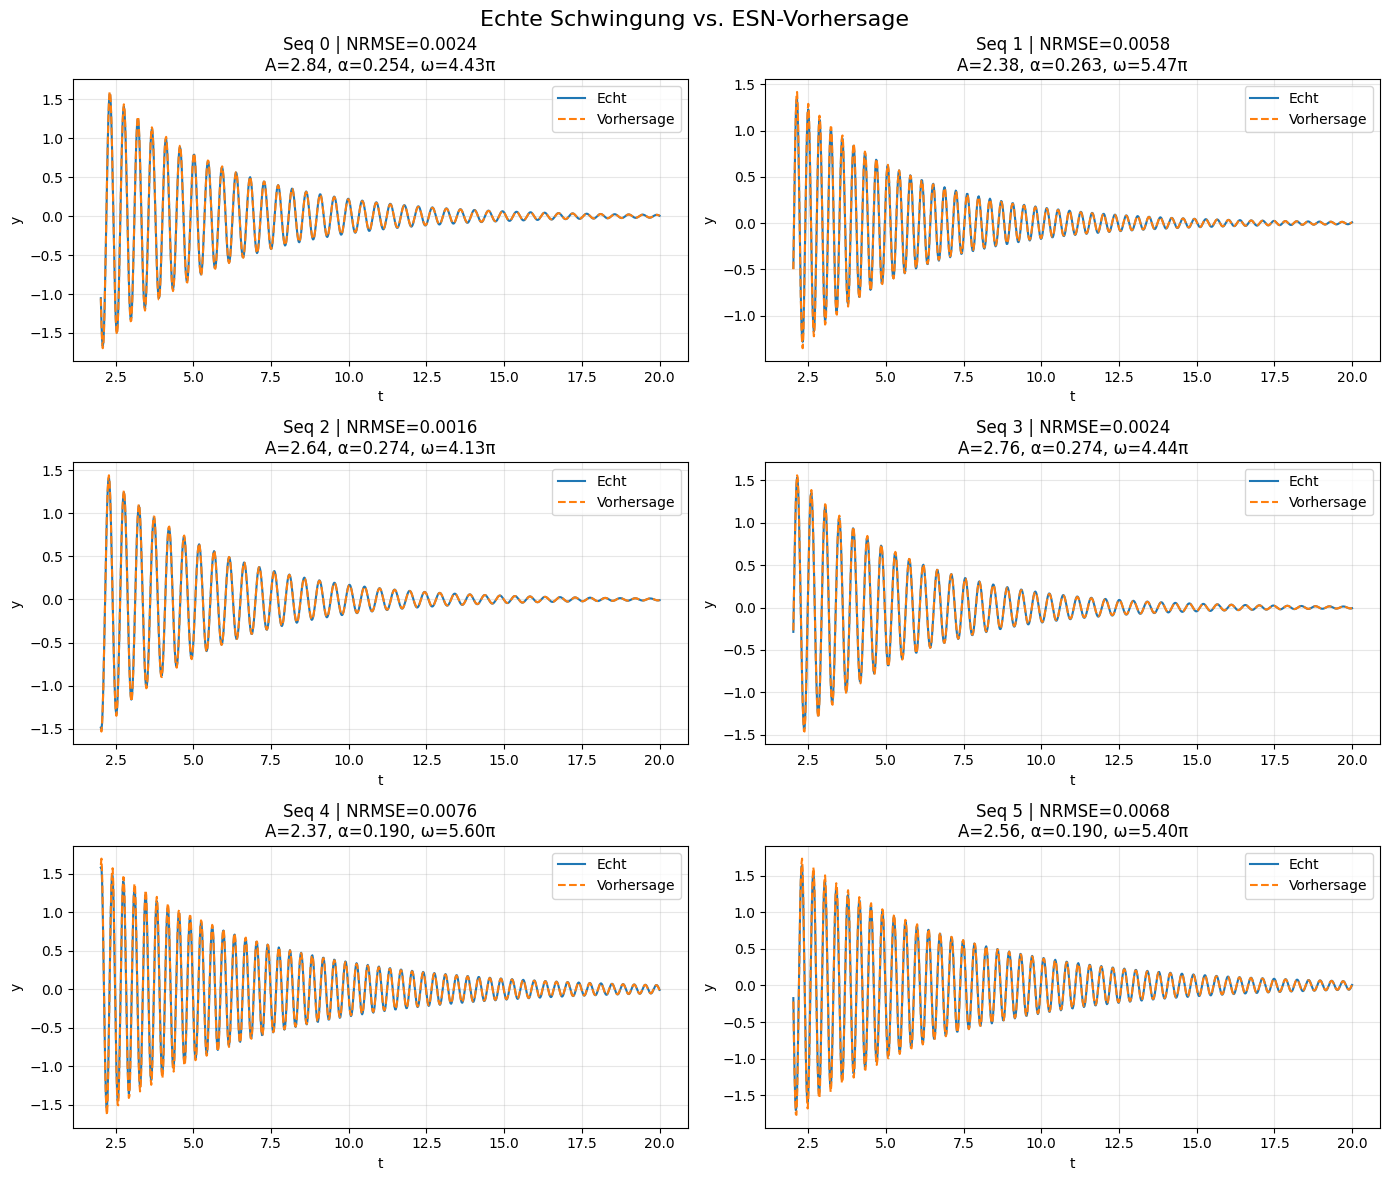

In [68]:
pu.plot_sequence_predictions(
    model_baseline, data_comb, nrmse_baseline_comb,
    n_examples=6, warmup=WARMUP, device=DEVICE,
)

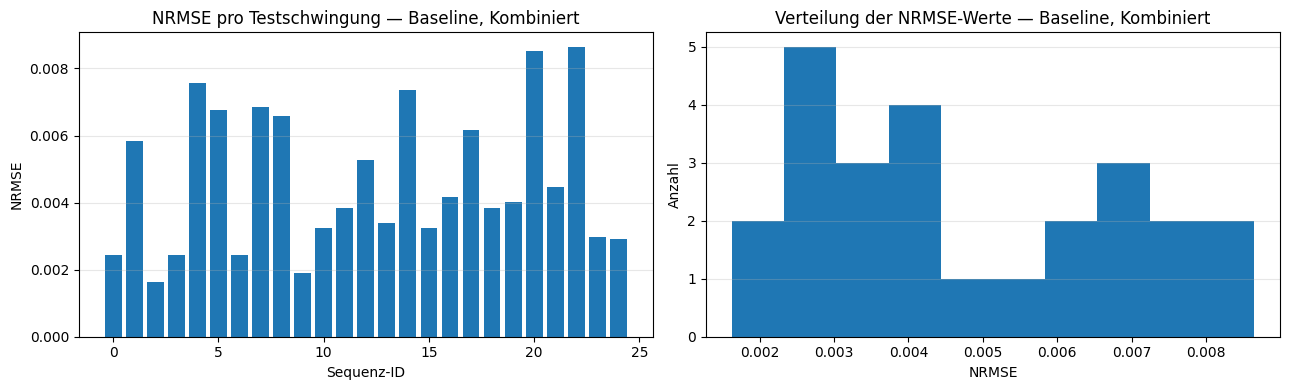

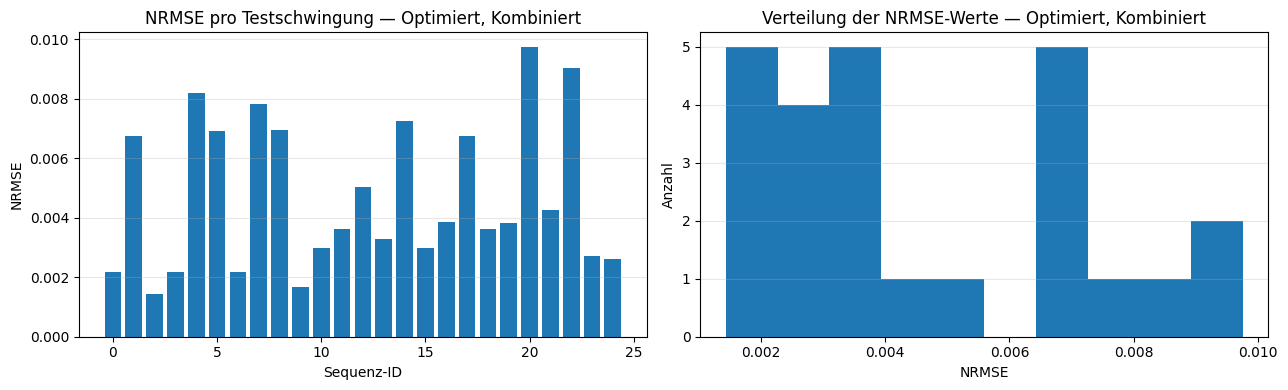

In [69]:
pu.plot_nrmse_distribution(nrmse_baseline_comb, title_suffix=" — Baseline, Kombiniert")
pu.plot_nrmse_distribution(nrmse_opt_comb,      title_suffix=" — Optimiert, Kombiniert")

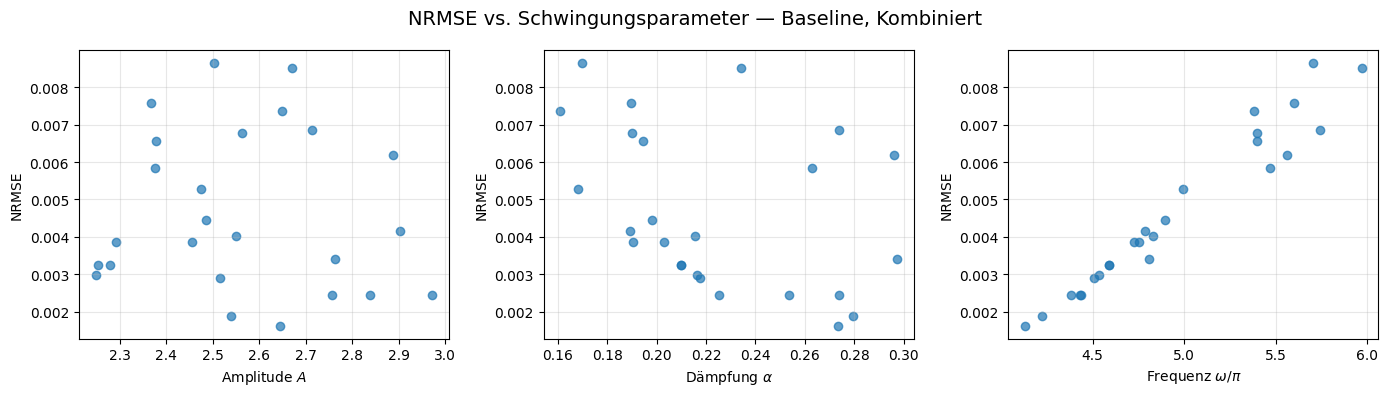

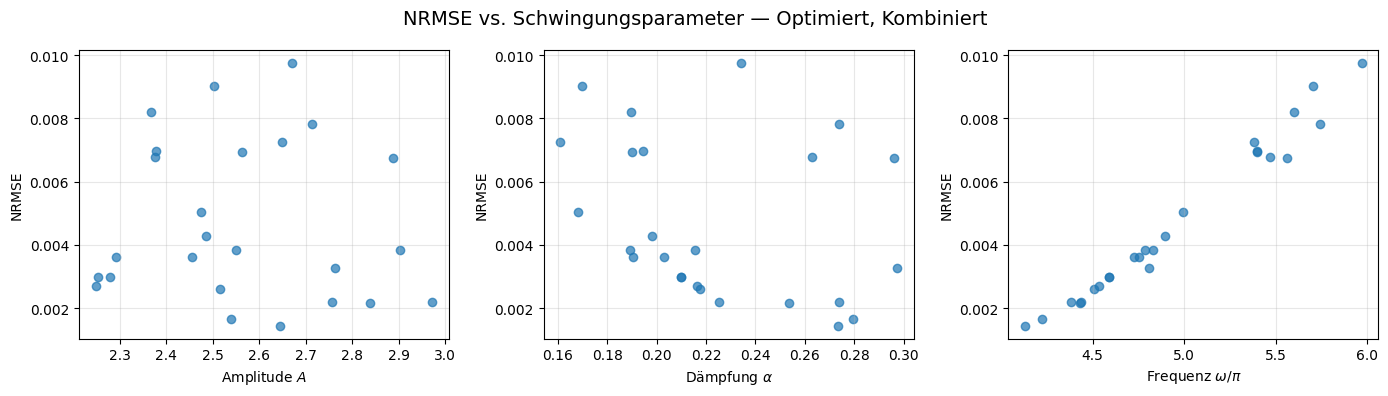

In [70]:
pu.plot_nrmse_vs_params(nrmse_baseline_comb, title_suffix="— Baseline, Kombiniert")
pu.plot_nrmse_vs_params(nrmse_opt_comb,      title_suffix="— Optimiert, Kombiniert")

**Beobachtung:**

Im kombinierten Szenario performen beide Modelle nahezu identisch: Baseline 0.004662, Optimiert 0.004712. Die erwartete Dominanz des optimierten Modells aus dem Amplitude-Szenario wird durch den Frequenzeffekt vollständig aufgehoben. Gleichzeitig mildert die starke Dämpfung ($\alpha \in [0.161, 0.297]$) den Frequenzeffekt ab, weil die Schwingungen früh abklingen und die schwierigen Hochfrequenzphasen kürzer andauern.

Der lineare Zusammenhang zwischen $\omega$ und NRMSE ist auch hier sichtbar: Innerhalb des kombinierten Datensatzes schneiden Sequenzen mit höherer Frequenz tendenziell besser ab, konsistent mit den Beobachtungen aus Szenario 3. Amplitude und Dämpfung zeigen keinen klaren systematischen Zusammenhang.

## 5.5. Gesamtvergleich

Das Balkendiagramm zeigt den mittleren NRMSE über alle fünf Szenarien (ID + 4 OOD) für beide Modelle. So ist direkt ablesbar, welches Szenario den grössten Einbruch verursacht und ob das optimierte Modell konsistent besser oder schlechter abschneidet als die Baseline.

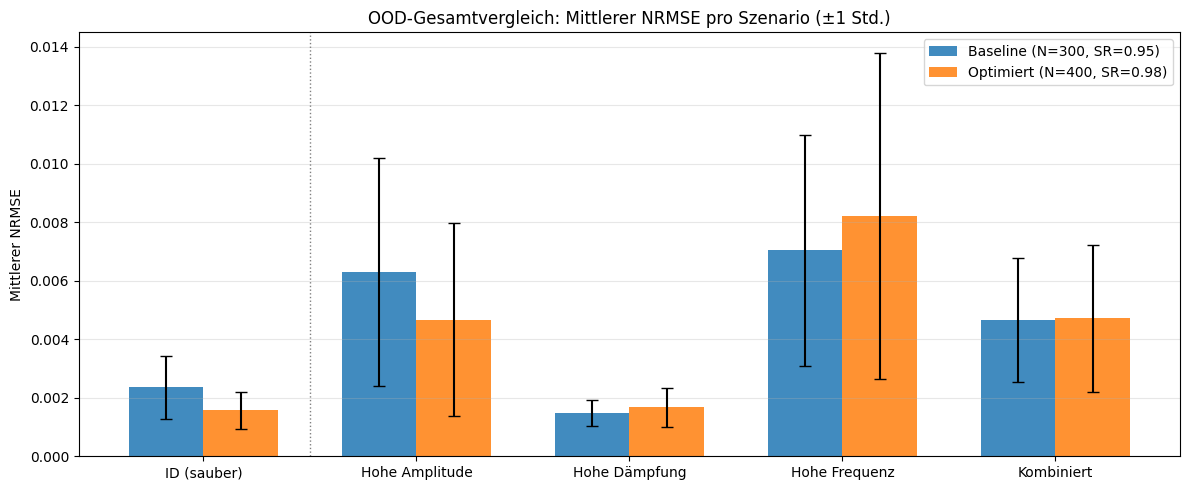

,Szenario,Baseline Mean NRMSE,Baseline Std,Optimiert Mean NRMSE,Optimiert Std,Faktor (OOD/ID) Baseline,Faktor (OOD/ID) Optimiert
0,ID (sauber),0.002358,0.001085,0.001578,0.000635,1.000000,1.000000
1,Hohe Amplitude,0.006308,0.003897,0.004672,0.003297,2.675708,2.961028
2,Hohe Dämpfung,0.001492,0.000441,0.001670,0.000676,0.632832,1.058521
3,Hohe Frequenz,0.007038,0.003961,0.008223,0.005584,2.985187,5.211790
4,Kombiniert,0.004662,0.002129,0.004712,0.002504,1.977465,2.986712


In [71]:
scenarios = ["ID (sauber)", "Hohe Amplitude", "Hohe Dämpfung", "Hohe Frequenz", "Kombiniert"]

means_baseline = [
    NRMSE_BASELINE_ID,
    nrmse_baseline_amp["nrmse"].mean(),
    nrmse_baseline_dmp["nrmse"].mean(),
    nrmse_baseline_frq["nrmse"].mean(),
    nrmse_baseline_comb["nrmse"].mean(),
]
stds_baseline = [
    nrmse_baseline_id["nrmse"].std(),
    nrmse_baseline_amp["nrmse"].std(),
    nrmse_baseline_dmp["nrmse"].std(),
    nrmse_baseline_frq["nrmse"].std(),
    nrmse_baseline_comb["nrmse"].std(),
]

means_opt = [
    NRMSE_OPT_ID,
    nrmse_opt_amp["nrmse"].mean(),
    nrmse_opt_dmp["nrmse"].mean(),
    nrmse_opt_frq["nrmse"].mean(),
    nrmse_opt_comb["nrmse"].mean(),
]
stds_opt = [
    eu.evaluate_model(model_opt, test_id_data, warmup=WARMUP, device=DEVICE)["nrmse"].std(),
    nrmse_opt_amp["nrmse"].std(),
    nrmse_opt_dmp["nrmse"].std(),
    nrmse_opt_frq["nrmse"].std(),
    nrmse_opt_comb["nrmse"].std(),
]

x = np.arange(len(scenarios))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 5))
bars_b = ax.bar(x - width / 2, means_baseline, width, yerr=stds_baseline, capsize=4,
                label="Baseline (N=300, SR=0.95)", color="tab:blue", alpha=0.85)
bars_o = ax.bar(x + width / 2, means_opt,      width, yerr=stds_opt,      capsize=4,
                label="Optimiert (N=400, SR=0.98)", color="tab:orange", alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.set_ylabel("Mittlerer NRMSE")
ax.set_title("OOD-Gesamtvergleich: Mittlerer NRMSE pro Szenario (±1 Std.)")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
ax.axvline(0.5, color="gray", linestyle=":", linewidth=1, label="ID / OOD Grenze")
plt.tight_layout()
plt.show()

comparison_df = pd.DataFrame({
    "Szenario": scenarios,
    "Baseline Mean NRMSE": means_baseline,
    "Baseline Std": stds_baseline,
    "Optimiert Mean NRMSE": means_opt,
    "Optimiert Std": stds_opt,
})
comparison_df["Faktor (OOD/ID) Baseline"] = comparison_df["Baseline Mean NRMSE"] / means_baseline[0]
comparison_df["Faktor (OOD/ID) Optimiert"] = comparison_df["Optimiert Mean NRMSE"] / means_opt[0]
comparison_df

**Beobachtung:**

Der Gesamtvergleich zeigt drei klare Muster:

**1. Hohe Frequenz ist der stärkste Stressfaktor.** Die Baseline verschlechtert sich gegenüber ID um Faktor ~2.9, das optimierte Modell um Faktor ~5.1. Kein anderes Einzelszenario kommt auch nur annähernd an diesen Einbruch heran.

**2. Hohe Dämpfung ist das einfachste OOD-Szenario.** Die Baseline erreicht sogar einen besseren NRMSE als auf den sauberen ID-Daten. Schnell abklingende Signale sind konzeptionell einfacher vorherzusagen.

**3. Das optimierte Modell ist nicht universell überlegen.** Es gewinnt klar bei hoher Amplitude, verliert aber bei hoher Frequenz und hoher Dämpfung. Der hohe Spektralradius ($\rho = 0.98$) ist auf langsam veränderliche ID-Daten optimiert; sobald die Dynamik schneller wird oder das Signal rasch abklingt, wird das lange Gedächtnis zum Nachteil. Die Baseline mit $\rho = 0.95$ ist in diesen Szenarien robuster.

## 5.6. Ergebnisse speichern

In [72]:
os.makedirs("results", exist_ok=True)
comparison_df.to_csv("results/ood_results.csv", index=False)

print("Gespeicherte Dateien:")
print("  results/ood_results.csv")

Gespeicherte Dateien:
  results/ood_results.csv


## 5.7. Fazit

Das ESN generalisiert unter OOD-Bedingungen unterschiedlich gut, abhängig davon, welcher Parameter ausserhalb des Trainingsbereichs liegt. Die Teilfrage *Wie stark bricht die Vorhersagegüte des ESN ein, wenn die Schwingungsparameter ausserhalb des Trainingsbereichs liegen?* lässt sich differenziert beantworten:

| Szenario | Baseline NRMSE | Faktor vs. ID | Optimiert NRMSE | Faktor vs. ID |
|---|---|---|---|---|
| ID (sauber) | 0.0024 | 1.0x | 0.0016 | 1.0x |
| Hohe Amplitude | 0.0063 | 2.6x | 0.0047 | 2.9x |
| Hohe Dämpfung | 0.0015 | 0.6x | 0.0017 | 1.0x |
| Hohe Frequenz | 0.0070 | 2.9x | 0.0082 | 5.1x |
| Kombiniert | 0.0047 | 1.9x | 0.0047 | 2.9x |

Hohe Frequenz ausserhalb des Trainingsbereichs ist der kritischste Faktor. Hohe Dämpfung hingegen vereinfacht die Vorhersage, weil das Signal früh gegen null konvergiert.

Ein zentrales Ergebnis ist die Umkehrung der Modellreihenfolge: Das optimierte Modell (N=400, SR=0.98) ist bei OOD-Amplitude besser, bei OOD-Frequenz und OOD-Dämpfung aber schlechter als die Baseline. Der hohe Spektralradius, der auf ID-Daten vorteilhaft ist, wird unter schnell veränderlicher oder schnell abklingender Dynamik zum Nachteil. Diese Beobachtung zeigt, dass eine auf ID-Daten optimierte Hyperparameterkonfiguration keine garantierte Überlegenheit unter Verteilungsverschiebung bietet.

---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="04_Rauschen_Robustheit.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="06_Schluss.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>